Exercises: 

Conceptual:

Exercise 1:

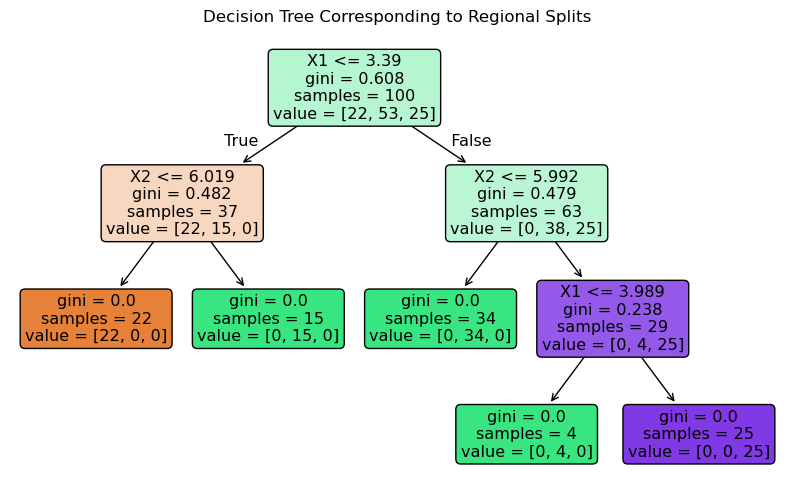

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree


np.random.seed(0)
n = 100
X1 = np.random.uniform(0, 10, size=n)
X2 = np.random.uniform(0, 10, size=n)

X_features = np.column_stack((X1, X2))
Y = (X1 > 4).astype(int) + (X2 > 6).astype(int)


tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_features, Y)

plt.figure(figsize=(10, 6))
plot_tree(
    tree_model,
    feature_names=["X1", "X2"],
    filled=True,
    rounded=True,
)
plt.title("Decision Tree Corresponding to Regional Splits")
plt.show()

Exercise 2:

Since every tree built in the sequence is restricted to being a stump, every tree's contribution depends on at most one predictor variable.

When you sum these individual univariate tree predictions together across the boosting iterations, the final model naturally takes the form of a sum of separate functions for each predictor:

$f(X) = \sum_{j=1}^p f_j(X_j)$

Exercise 3:

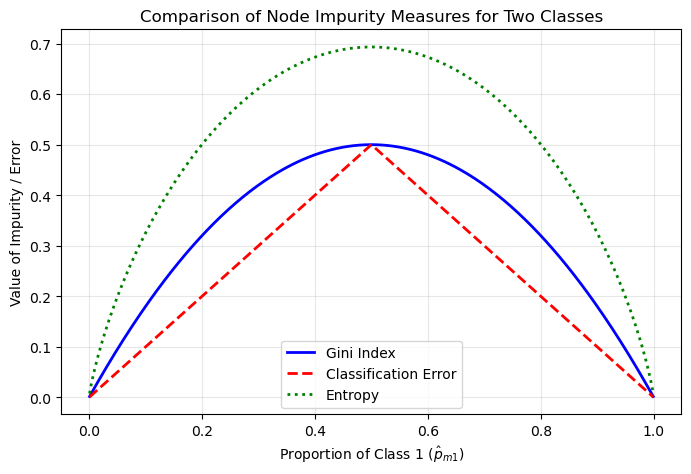

In [2]:

p1 = np.linspace(0.001, 0.999, 400)  # avoid exact 0 for log in entropy
p2 = 1 - p1


gini = 2 * p1 * p2
classification_error = 1 - np.maximum(p1, p2)
entropy = -(p1 * np.log(p1) + p2 * np.log(p2))


plt.figure(figsize=(8, 5))
plt.plot(p1, gini, label="Gini Index", color="blue", linewidth=2)
plt.plot(
    p1, classification_error, label="Classification Error", color="red", linestyle="--", linewidth=2
)
plt.plot(p1, entropy, label="Entropy", color="green", linestyle=":", linewidth=2)

plt.title("Comparison of Node Impurity Measures for Two Classes")
plt.xlabel("Proportion of Class 1 ($\hat{p}_{m1}$)")
plt.ylabel("Value of Impurity / Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Exercise 4:

(a) Tree Structure from the Partition Map
To trace the tree from the left-hand panel:
1. **First split ($X_1 = 1$):** 
   - If $X_1 \ge 1 \rightarrow$ Region ends with a mean of **$5$**.
   - If $X_1 < 1 \rightarrow$ Move to the next split.
2. **Second split ($X_2 = 1$):** 
   - If $X_2 \ge 1 \rightarrow$ Region ends with a mean of **$15$**.
   - If $X_2 < 1 \rightarrow$ Move to the next split.
3. **Third split ($X_1 = 0$):** 
   - If $X_1 < 0 \rightarrow$ Region ends with a mean of **$3$**.
   - If $X_1 \ge 0 \rightarrow$ Move to the final split.
4. **Fourth split ($X_2 = 0$):** 
   - If $X_2 < 0 \rightarrow$ Region ends with a mean of **$10$**.
   - If $X_2 \ge 0 \rightarrow$ Region ends with a mean of **$0$**.




(b) Partition Map from the Tree Rules
To draw the partition map from the right-hand panel:
1. **Root Node ($X_2 < 1$):** Splits the entire space horizontally at $X_2 = 1$.
2. **Left Branch ($X_2 < 1$):** 
   - Split vertically at $X_1 = 1$, creating two regions:
     - $X_1 < 1 \rightarrow$ Mean = **$-1.80$**
     - $X_1 \ge 1 \rightarrow$ Mean = **$0.63$**
3. **Right Branch ($X_2 \ge 1$):** 
   - Split horizontally at $X_2 = 2$, creating a top strip ($X_2 \ge 2$, Mean = **$2.49$**) and a middle strip ($1 \le X_2 < 2$).
   - The middle strip is further split vertically at $X_1 = 0$:
     - $X_1 < 0 \rightarrow$ Mean = **$-1.06$**
     - $X_1 \ge 0 \rightarrow$ Mean = **$0.21$**

Exercise 5:

Majority Vote (Hard Voting)

**Mechanism:** Each of the 10 trees casts a single vote for its predicted class based on whether its probability estimate exceeds $0.5$.
* **Counting Votes:** 
  * Probabilities $\le 0.5$ ($0.1, 0.15, 0.2, 0.2$): **4 trees** vote for **Green**.
  * Probabilities $> 0.5$ ($0.55, 0.6, 0.6, 0.65, 0.7, 0.75$): **6 trees** vote for **Red**.
* **Final Classification:** **Red** wins by a 6-to-4 majority.



Average Probability (Soft Voting)
**Mechanism:** We average the probability estimates directly across all 10 trees first, and then classify based on that combined average.
* **Calculation:**
  $\text{Average} = \frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.5}{10} = 0.45$
* **Final Classification:** Since the average probability ($0.45$) is less than $0.5$, the combined model classifies the point as **Green**.


Exercise 6:


1. **Grow the Full Tree:** We start with the training data and use recursive binary splitting to grow a large, complex tree. We keep splitting until nodes hit a minimum sample size threshold.

2. **The Overfitting Trap:** Because this large tree grows too complex, it overfits the training data (low bias, massive variance).

3. **Cost-Complexity Pruning :** To fix this, we introduce a tuning parameter $\alpha$ that penalizes the tree for having too many leaves. This allows us to systematically "prune" back the weakest branches, creating a sequence of nested subtrees.

4. **Model Selection via Cross-Validation:** We use K-fold cross-validation across our training data to test different values of $\alpha$. By measuring the out-of-fold Mean Squared Error (MSE), we find the optimal $\alpha$ that gives us the best balance—reducing variance so the model generalizes well to unseen test data.

Applied:

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from ISLP import load_data

from sklearn.tree import (DecisionTreeClassifier as DTC,DecisionTreeRegressor as DTR,plot_tree,export_text)
from sklearn.metrics import (accuracy_score,log_loss)
from sklearn.ensemble import (RandomForestRegressor as RF,GradientBoostingRegressor as GBR)

Exercise 7:

In [7]:
boston = load_data('boston')


In [18]:
from sklearn.model_selection import train_test_split
from ISLP.models import ModelSpec as MS
model = MS(boston.columns.drop('medv'), intercept=False)
D = model.fit_transform(boston)
feature_names = list(D.columns)
X = np.asarray(D)
y = boston['medv']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0)

In [19]:
len(feature_names)

12

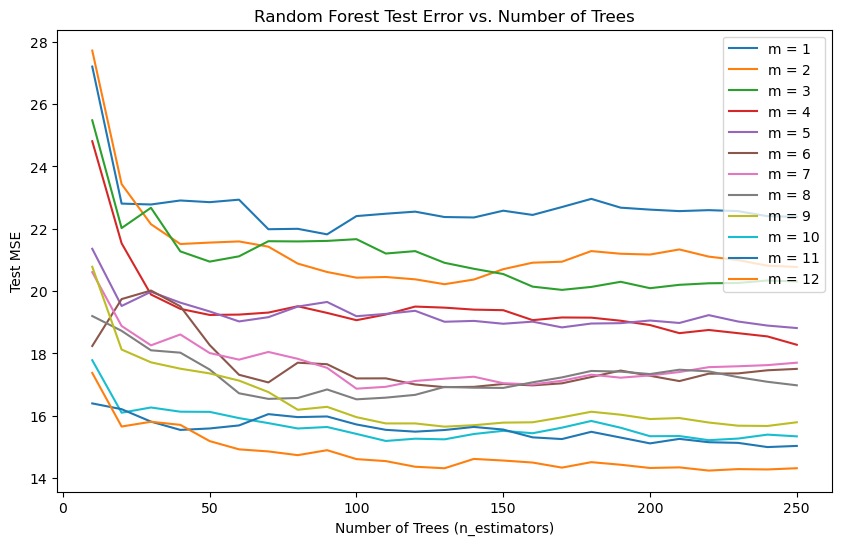

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error

tree_counts = np.arange(10, 251, 10)
feature_counts = range(1, X_train.shape[1] + 1)

plt.figure(figsize=(10, 6))

for m in feature_counts:
  test_errors = []
  for n in tree_counts:
    rf = RF(n_estimators=n, max_features=m, random_state=1)
    rf.fit(X_train, y_train)
    preds = rf.predict(X_test)
    test_errors.append(mean_squared_error(y_test, preds))

  plt.plot(tree_counts, test_errors, label=f"m = {m}")

plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Test MSE")
plt.title("Random Forest Test Error vs. Number of Trees")
plt.legend()
plt.show()

Exercise 8:

In [24]:
carseats = load_data('Carseats')

In [26]:
model = MS(carseats.columns.drop('Sales'), intercept=False)
D = model.fit_transform(carseats)
feature_names = list(D.columns)
X = np.asarray(D)
y = carseats['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0)

Test MSE: 3.7038582752360933


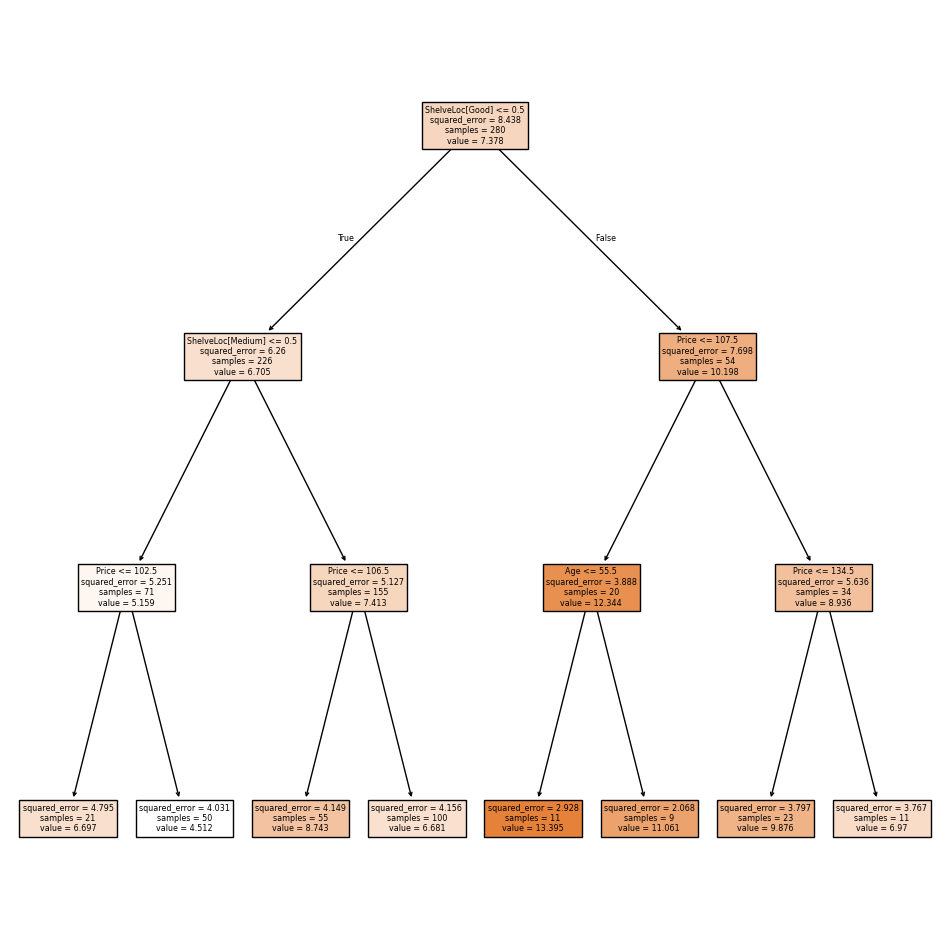

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error


y_pred = reg.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred)
print(f"Test MSE: {test_mse}")


fig, ax = plt.subplots(figsize=(12, 12))
plot_tree(reg, feature_names=feature_names, ax=ax, filled=True)
plt.show()

In [31]:
#(c)

from sklearn.model_selection import cross_val_score

base_tree = DTR(random_state=0)
path = base_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

cv_scores = []
for alpha in ccp_alphas:
  tree = DTR(random_state=0, ccp_alpha=alpha)
  scores = cross_val_score(
      tree, X_train, y_train, cv=10, scoring="neg_mean_squared_error"
  )
  cv_scores.append(-np.mean(scores))


optimal_alpha = ccp_alphas[np.argmin(cv_scores)]
print('Optimal ccp_alpha:', optimal_alpha)

Optimal ccp_alpha: 0.007965761904761948


In [32]:
from sklearn.metrics import mean_squared_error


pruned_tree = DTR(random_state=0, ccp_alpha=optimal_alpha)
pruned_tree.fit(X_train, y_train)


y_pred_pruned = pruned_tree.predict(X_test)
pruned_test_mse = mean_squared_error(y_test, y_pred_pruned)

print(f"Pruned Tree Test MSE: {pruned_test_mse}")

Pruned Tree Test MSE: 4.437382372716606


The Tree just got worse!!!

In [33]:
#(d)

bag_carseats = RF(max_features=X_train.shape[1], n_estimators=500, random_state=0)
bag_carseats.fit(X_train, y_train)


bag_preds = bag_carseats.predict(X_test)
bag_test_mse = mean_squared_error(y_test, bag_preds)
print('Bagging Test MSE:', bag_test_mse)


importances = pd.Series(bag_carseats.feature_importances_, index=feature_names)
print(importances.sort_values(ascending=False))

Bagging Test MSE: 2.0236328641333428
Price                0.286600
ShelveLoc[Good]      0.220007
Age                  0.105353
CompPrice            0.100679
ShelveLoc[Medium]    0.085092
Advertising          0.068876
Income               0.053628
Population           0.039242
Education            0.029639
US[Yes]              0.006542
Urban[Yes]           0.004342
dtype: float64


Price (0.287) and ShelveLoc[Good] (0.220) are far and away the most dominant variables in driving sales predictions. Together, they account for over 50% of the model's total error reduction.

In [34]:
#(e)

rf_carseats = RF(
    max_features=4, n_estimators=500, random_state=0
) 
rf_carseats.fit(X_train, y_train)

rf_preds = rf_carseats.predict(X_test)
rf_test_mse = mean_squared_error(y_test, rf_preds)
print(f"Random Forest Test MSE: {rf_test_mse}")

Random Forest Test MSE: 2.124181374920006


In [35]:
rf_importances = pd.Series(rf_carseats.feature_importances_, index=feature_names)
print(rf_importances.sort_values(ascending=False))

Price                0.254391
ShelveLoc[Good]      0.178323
Age                  0.118737
CompPrice            0.097030
Advertising          0.082273
Income               0.079530
Population           0.065747
ShelveLoc[Medium]    0.055386
Education            0.044850
US[Yes]              0.013415
Urban[Yes]           0.010318
dtype: float64


Top Variables: Price and ShelveLoc[Good] consistently dominate the list, accounting for the vast majority of the model's total impurity/error reduction

In [36]:
#(f)

from ISLP.bart import BART
from sklearn.metrics import mean_squared_error


bart_carseats = BART(random_state=0)
bart_carseats.fit(X_train, y_train)

bart_preds = bart_carseats.predict(X_test)
bart_test_mse = mean_squared_error(y_test, bart_preds)

print(f"BART Test MSE: {bart_test_mse}")

BART Test MSE: 1.6054894072506285


Exercise 9:


In [37]:
oj = load_data('OJ')

In [38]:
oj.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Purchase        1070 non-null   category
 1   WeekofPurchase  1070 non-null   int64   
 2   StoreID         1070 non-null   int64   
 3   PriceCH         1070 non-null   float64 
 4   PriceMM         1070 non-null   float64 
 5   DiscCH          1070 non-null   float64 
 6   DiscMM          1070 non-null   float64 
 7   SpecialCH       1070 non-null   int64   
 8   SpecialMM       1070 non-null   int64   
 9   LoyalCH         1070 non-null   float64 
 10  SalePriceMM     1070 non-null   float64 
 11  SalePriceCH     1070 non-null   float64 
 12  PriceDiff       1070 non-null   float64 
 13  Store7          1070 non-null   category
 14  PctDiscMM       1070 non-null   float64 
 15  PctDiscCH       1070 non-null   float64 
 16  ListPriceDiff   1070 non-null   float64 
 17  STORE         

In [39]:
model = MS(oj.columns.drop('Purchase'), intercept=False)
D = model.fit_transform(oj)
feature_names = list(D.columns)
X = np.asarray(D)
y = oj['Purchase']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)

In [46]:
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.metrics import accuracy_score

clf = DTC(random_state=0)
clf.fit(X_train, y_train)


y_train_pred = clf.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
train_error_rate = 1 - train_accuracy

print(f"Training Error Rate: {train_error_rate:.4f}")

Training Error Rate: 0.0087


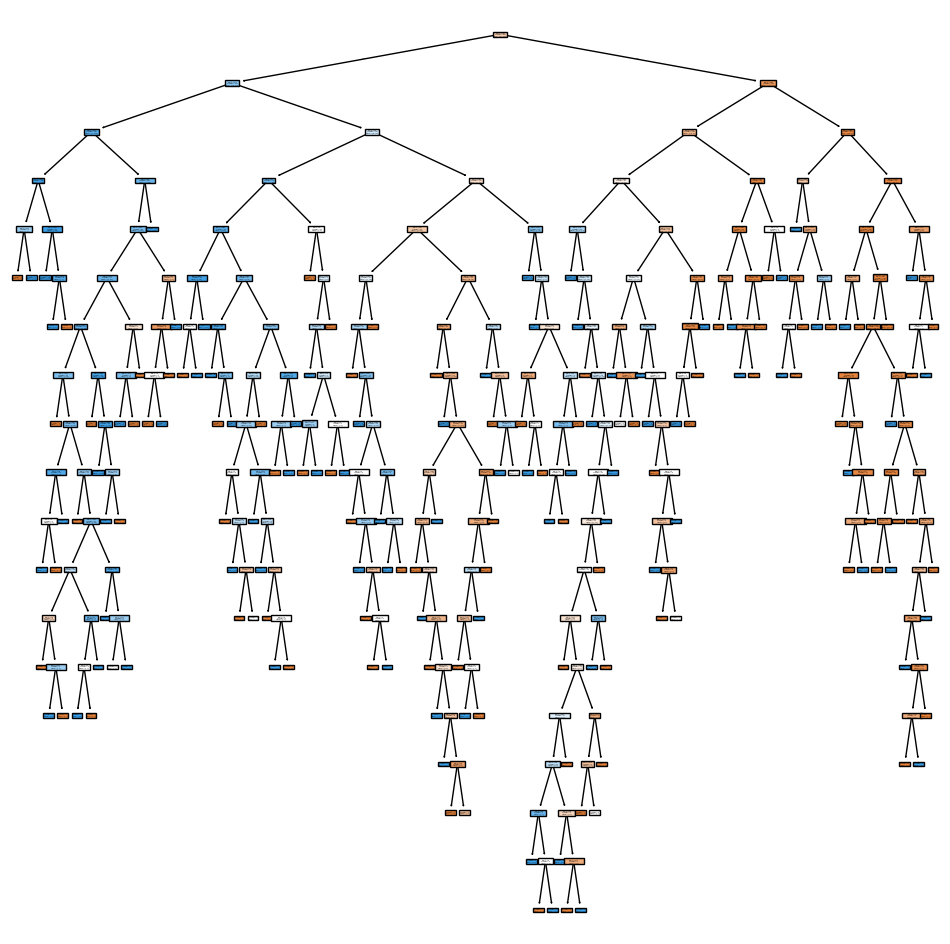

In [47]:
fig, ax = plt.subplots(figsize=(12, 12))
plot_tree(clf, feature_names=feature_names, ax=ax, filled=True)
plt.show()

In [48]:
from sklearn.tree import export_text

tree_text = export_text(clf, feature_names=feature_names)
print(tree_text)

|--- LoyalCH <= 0.51
|   |--- LoyalCH <= 0.28
|   |   |--- LoyalCH <= 0.06
|   |   |   |--- StoreID <= 1.50
|   |   |   |   |--- ListPriceDiff <= 0.15
|   |   |   |   |   |--- class: CH
|   |   |   |   |--- ListPriceDiff >  0.15
|   |   |   |   |   |--- class: MM
|   |   |   |--- StoreID >  1.50
|   |   |   |   |--- WeekofPurchase <= 268.50
|   |   |   |   |   |--- class: MM
|   |   |   |   |--- WeekofPurchase >  268.50
|   |   |   |   |   |--- LoyalCH <= 0.00
|   |   |   |   |   |   |--- class: MM
|   |   |   |   |   |--- LoyalCH >  0.00
|   |   |   |   |   |   |--- class: CH
|   |   |--- LoyalCH >  0.06
|   |   |   |--- WeekofPurchase <= 273.50
|   |   |   |   |--- SalePriceCH <= 1.94
|   |   |   |   |   |--- WeekofPurchase <= 263.50
|   |   |   |   |   |   |--- STORE <= 1.50
|   |   |   |   |   |   |   |--- WeekofPurchase <= 228.00
|   |   |   |   |   |   |   |   |--- class: CH
|   |   |   |   |   |   |   |--- WeekofPurchase >  228.00
|   |   |   |   |   |   |   |   |--- LoyalCH <= 

In [50]:
#(e)

from sklearn.metrics import accuracy_score, confusion_matrix



y_test_pred = clf.predict(X_test)
conf_mat = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
display(conf_mat) 


test_accuracy = accuracy_score(y_test, y_test_pred)
test_error_rate = 1 - test_accuracy

print('Test Error Rate:', test_error_rate)

Confusion Matrix:


array([[115,  37],
       [ 35,  81]])

Test Error Rate: 0.26865671641791045


In [51]:
# (f)
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas


cv_scores = []
for alpha in ccp_alphas:
  tree = DTC(random_state=0, ccp_alpha=alpha)
  scores = cross_val_score(tree, X_train, y_train, cv=10, scoring="accuracy")
  cv_scores.append(np.mean(scores))

optimal_alpha_idx = np.argmax(cv_scores)
optimal_alpha = ccp_alphas[optimal_alpha_idx]

print('Optimal ccp_alpha:', optimal_alpha)

Optimal ccp_alpha: 0.0036817326882486526


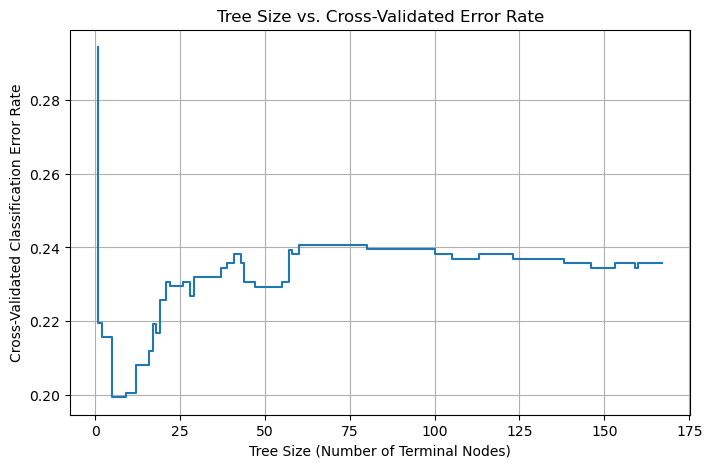

In [53]:
#(g)

ccp_alphas = path.ccp_alphas
node_counts = []
cv_error_rates = []

for alpha in ccp_alphas:
  tree = DTC(random_state=0, ccp_alpha=alpha)
  tree.fit(X_train, y_train)

  node_counts.append(tree.get_n_leaves())


  scores = cross_val_score(tree, X_train, y_train, cv=10, scoring="accuracy")
  cv_error_rates.append(1 - np.mean(scores))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(node_counts, cv_error_rates,  drawstyle="steps-post")
ax.set_xlabel("Tree Size (Number of Terminal Nodes)")
ax.set_ylabel("Cross-Validated Classification Error Rate")
ax.set_title("Tree Size vs. Cross-Validated Error Rate")
plt.grid(True)
plt.show()

In [55]:
#(h)

min_error_idx = np.argmin(cv_error_rates)
optimal_tree_size = node_counts[min_error_idx]

print(f"Optimal number of terminal nodes: {optimal_tree_size}")
print(f"Corresponding lowest CV error rate: {cv_error_rates[min_error_idx]:.4f}")

Optimal number of terminal nodes: 9
Corresponding lowest CV error rate: 0.1994


In [57]:
# (i)
pruned_clf = DTC(random_state=0, ccp_alpha=optimal_alpha)
pruned_clf.fit(X_train, y_train)

print('Pruned tree leaf count:', pruned_clf.get_n_leaves())

Pruned tree leaf count: 9


In [59]:
#(j)
from sklearn.metrics import accuracy_score


train_pred_unpruned = clf.predict(X_train)
train_err_unpruned = 1 - accuracy_score(y_train, train_pred_unpruned)


train_pred_pruned = pruned_clf.predict(X_train)
train_err_pruned = 1 - accuracy_score(y_train, train_pred_pruned)

print(f"Unpruned Training Error Rate: {train_err_unpruned:.4f}")
print(f"Pruned Training Error Rate: {train_err_pruned:.4f}")

Unpruned Training Error Rate: 0.0087
Pruned Training Error Rate: 0.1534


An unpruned tree grows as large as possible to fit the training data perfectly, minimizing training error to a fault (overfitting). 
Pruning deliberately chops off branches, making the training fit slightly less exact in exchange for better generalization

In [60]:
#(k)

test_pred_unpruned = clf.predict(X_test)
test_err_unpruned = 1 - accuracy_score(y_test, test_pred_unpruned)


test_pred_pruned = pruned_clf.predict(X_test)
test_err_pruned = 1 - accuracy_score(y_test, test_pred_pruned)

print(f"Unpruned Test Error Rate: {test_err_unpruned:.4f}")
print(f"Pruned Test Error Rate: {test_err_pruned:.4f}")

Unpruned Test Error Rate: 0.2687
Pruned Test Error Rate: 0.2201


Even though the unpruned tree is better at memorizing the training data, pruning removes noise and overfitting, allowing the pruned tree to generalize better and achieve a lower error rate on the test set.

Exercise 10:

In [70]:
hitters = load_data('Hitters')

In [71]:
hitters.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   AtBat      322 non-null    int64   
 1   Hits       322 non-null    int64   
 2   HmRun      322 non-null    int64   
 3   Runs       322 non-null    int64   
 4   RBI        322 non-null    int64   
 5   Walks      322 non-null    int64   
 6   Years      322 non-null    int64   
 7   CAtBat     322 non-null    int64   
 8   CHits      322 non-null    int64   
 9   CHmRun     322 non-null    int64   
 10  CRuns      322 non-null    int64   
 11  CRBI       322 non-null    int64   
 12  CWalks     322 non-null    int64   
 13  League     322 non-null    category
 14  Division   322 non-null    category
 15  PutOuts    322 non-null    int64   
 16  Assists    322 non-null    int64   
 17  Errors     322 non-null    int64   
 18  Salary     263 non-null    float64 
 19  NewLeague  322 non-null    ca

In [72]:

from ISLP.models import ModelSpec as MS

hitters = hitters.dropna(subset=['Salary'])

y = np.log(hitters['Salary'])
design = MS(hitters.columns.drop('Salary'), intercept=False)
D = design.fit_transform(hitters)
feature_names = list(D.columns)
X = np.asarray(D)

X_train, X_test = X[:200], X[200:]
y_train, y_test = y[:200], y[200:]

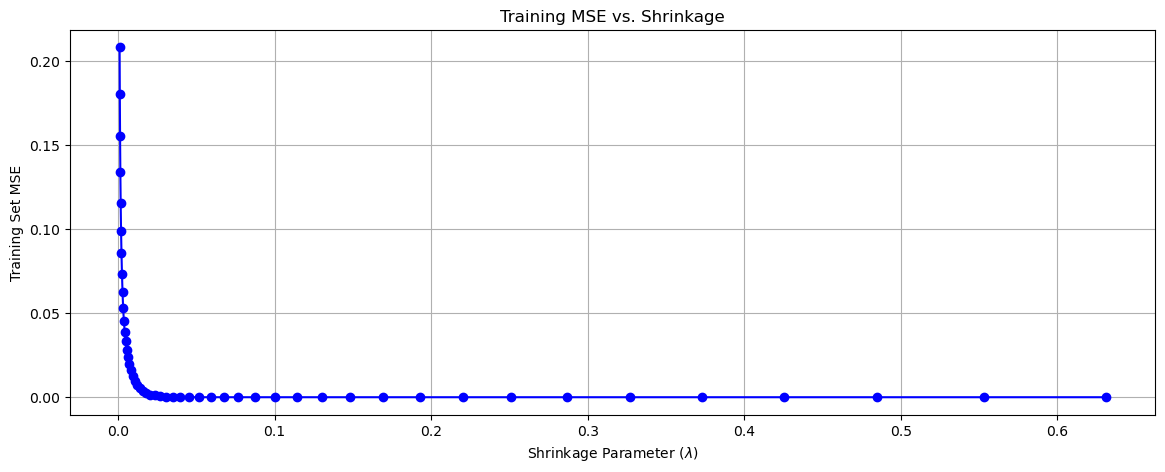

In [75]:
#(c)

from sklearn.ensemble import GradientBoostingRegressor

lambdas = np.logspace(-3, -0.2, 50)

train_mse = []
test_mse = []

for lam in lambdas:
  boost_hitters = GradientBoostingRegressor(
      n_estimators=1000, learning_rate=lam, random_state=0 )
  boost_hitters.fit(X_train, y_train)

 
  train_preds = boost_hitters.predict(X_train)
  train_mse.append(mean_squared_error(y_train, train_preds))

 
  test_preds = boost_hitters.predict(X_test)
  test_mse.append(mean_squared_error(y_test, test_preds))


fig,ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(lambdas, train_mse, marker='o', color='b')
ax1.set_xlabel('Shrinkage Parameter ($\lambda$)')
ax1.set_ylabel('Training Set MSE')
ax1.set_title('Training MSE vs. Shrinkage')
ax1.grid(True)



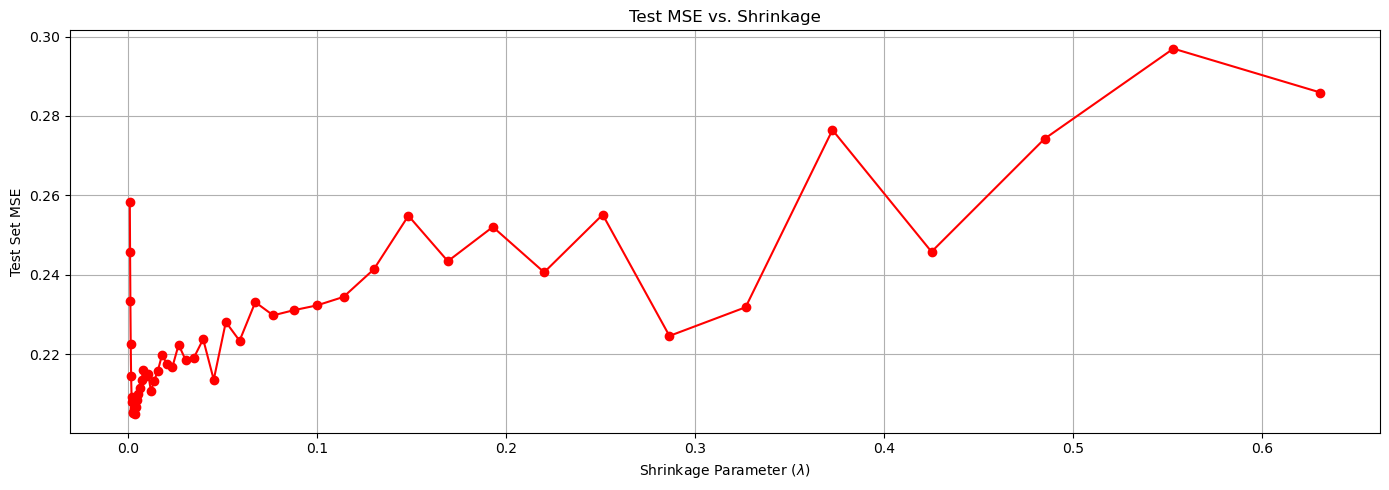

Optimal Shrinkage lambda 0.003727593720314938
Lowest Test MSE: 0.2048631402749961


In [80]:
#  (d)
fig,ax2 = plt.subplots(figsize=(14, 5))
ax2.plot(lambdas, test_mse, marker='o', color='r')
ax2.set_xlabel('Shrinkage Parameter ($\lambda$)')
ax2.set_ylabel('Test Set MSE')
ax2.set_title('Test MSE vs. Shrinkage')
ax2.grid(True)

plt.tight_layout()
plt.show()

optimal_lambda = lambdas[np.argmin(test_mse)]
print('Optimal Shrinkage lambda', optimal_lambda)
print('Lowest Test MSE:', min(test_mse))

In [82]:
#(e)

from sklearn.linear_model import LinearRegression, Ridge

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)
lr_test_mse = mean_squared_error(y_test, lr_preds)


ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_preds = ridge.predict(X_test)
ridge_test_mse = mean_squared_error(y_test, ridge_preds)

print('Boosting Test MSE:', min(test_mse))
print('Linear Regression Test MSE',lr_test_mse)
print('Ridge Regression Test MSE',ridge_test_mse)

Boosting Test MSE: 0.2048631402749961
Linear Regression Test MSE 0.491795937545495
Ridge Regression Test MSE 0.49277626094574467


In [85]:
best_boost = GradientBoostingRegressor(n_estimators=1000, learning_rate=optimal_lambda, random_state=0)
best_boost.fit(X_train, y_train)

boost_importances = pd.Series(best_boost.feature_importances_, index=feature_names)
print(boost_importances.sort_values(ascending=False))

CAtBat          0.551969
CHits           0.096184
CRuns           0.053478
AtBat           0.048846
Walks           0.045689
CRBI            0.038482
CWalks          0.034484
CHmRun          0.031232
Years           0.025179
Hits            0.023542
RBI             0.016337
PutOuts         0.012440
Runs            0.010720
Errors          0.004909
Assists         0.002548
HmRun           0.001642
NewLeague[N]    0.001307
League[N]       0.000552
Division[W]     0.000459
dtype: float64


In [86]:
#(g)
from sklearn.ensemble import RandomForestRegressor as RFR

bag_hitters = RFR(max_features=X_train.shape[1], n_estimators=500, random_state=0)
bag_hitters.fit(X_train, y_train)

bag_preds = bag_hitters.predict(X_test)
bag_test_mse = mean_squared_error(y_test, bag_preds)

print('Bagging Test MSE:', bag_test_mse)

Bagging Test MSE: 0.22978936372707165


Both bagging and boosting provide strong improvements over single trees by reducing variance

Exercise 12:

In [87]:
caravan = load_data('Caravan')
caravan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 86 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   MOSTYPE   5822 non-null   int64   
 1   MAANTHUI  5822 non-null   int64   
 2   MGEMOMV   5822 non-null   int64   
 3   MGEMLEEF  5822 non-null   int64   
 4   MOSHOOFD  5822 non-null   int64   
 5   MGODRK    5822 non-null   int64   
 6   MGODPR    5822 non-null   int64   
 7   MGODOV    5822 non-null   int64   
 8   MGODGE    5822 non-null   int64   
 9   MRELGE    5822 non-null   int64   
 10  MRELSA    5822 non-null   int64   
 11  MRELOV    5822 non-null   int64   
 12  MFALLEEN  5822 non-null   int64   
 13  MFGEKIND  5822 non-null   int64   
 14  MFWEKIND  5822 non-null   int64   
 15  MOPLHOOG  5822 non-null   int64   
 16  MOPLMIDD  5822 non-null   int64   
 17  MOPLLAAG  5822 non-null   int64   
 18  MBERHOOG  5822 non-null   int64   
 19  MBERZELF  5822 non-null   int64   
 20  MBERBOER

In [98]:
design = MS(caravan.columns.drop('Purchase'))
D = design.fit_transform(caravan)
feature_names = list(D.columns)
X = np.asarray(D)
y = (caravan['Purchase'] == 'Yes').astype(int)

X_train, X_test = X[:1000], X[1000:]
y_train, y_test = y[:1000], y[1000:]

In [99]:
from sklearn.ensemble import GradientBoostingClassifier
boost_caravan = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.01, random_state=0)
boost_caravan.fit(X_train, y_train)

importances = pd.Series(boost_caravan.feature_importances_, index=feature_names)
print(importances.sort_values(ascending=False))

PPERSAUT     0.076543
MOSTYPE      0.065716
ABRAND       0.058196
MGODGE       0.052989
MKOOPKLA     0.048259
               ...   
AVRAAUT      0.000000
PBESAUT      0.000000
PVRAAUT      0.000000
PWERKT       0.000000
intercept    0.000000
Length: 86, dtype: float64


In [100]:
#(c)

probs = boost_caravan.predict_proba(X_test)[:, 1]
y_test_pred = (probs > 0.20) 

cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
print(cm)

true_positives = cm[1, 1]
total_predicted_positive = cm[0, 1] + cm[1, 1]

fraction = (
    true_positives / total_predicted_positive
    if total_predicted_positive > 0
    else 0
)
print(
    f"\nFraction of predicted purchasers who actually bought: {fraction:.4f} ("
    f"{fraction*100:.1f}%)"
)

Confusion Matrix:
[[4336  197]
 [ 252   37]]

Fraction of predicted purchasers who actually bought: 0.1581 (15.8%)


Exercise 12:

In [105]:
braincancer = load_data('BrainCancer')
braincancer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   sex        88 non-null     category
 1   diagnosis  87 non-null     category
 2   loc        88 non-null     category
 3   ki         88 non-null     int64   
 4   gtv        88 non-null     float64 
 5   stereo     88 non-null     category
 6   status     88 non-null     int64   
 7   time       88 non-null     float64 
dtypes: category(4), float64(2), int64(2)
memory usage: 3.8 KB


In [109]:
braincancer['loc'].unique()
braincancer.dropna()

,sex,diagnosis,loc,ki,gtv,stereo,status,time
0,Female,Meningioma,Infratentorial,90,6.11,SRS,0,57.64
1,Male,HG glioma,Supratentorial,90,19.35,SRT,1,8.98
2,Female,Meningioma,Infratentorial,70,7.95,SRS,0,26.46
3,Female,LG glioma,Supratentorial,80,7.61,SRT,1,47.80
4,Male,HG glioma,Supratentorial,90,5.06,SRT,1,6.30
...,...,...,...,...,...,...,...,...
83,Male,HG glioma,Supratentorial,80,0.16,SRT,1,20.69
84,Male,HG glioma,Supratentorial,80,19.81,SRT,1,6.39
85,Male,Meningioma,Supratentorial,90,2.50,SRT,0,32.82
86,Male,Meningioma,Supratentorial,90,2.02,SRS,0,42.07


In [110]:
design = MS(braincancer.columns.drop('loc'))
D = design.fit_transform(braincancer)
feature_names = list(D.columns)
X = np.asarray(D)
y = (braincancer['loc'] == 'Infratentorial').astype(int)

In [111]:
X_train, X_test = X[:50], X[50:]
y_train, y_test = y[:50], y[50:]

In [113]:
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



# --- Model 1: Logistic Regression  ---
log_reg = LogisticRegression(max_iter=1000, random_state=0)
log_reg.fit(X_train, y_train)
log_pred = log_reg.predict(X_test)
log_acc = accuracy_score(y_test, log_pred)

# --- Model 2: Gradient Boosting ---
boost = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.01, random_state=0
)
boost.fit(X_train, y_train)
boost_pred = boost.predict(X_test)
boost_acc = accuracy_score(y_test, boost_pred)

# --- Model 3: Bagging ---
bag = BaggingClassifier(
    n_estimators=100, random_state=0
) 
bag.fit(X_train, y_train)
bag_pred = bag.predict(X_test)
bag_acc = accuracy_score(y_test, bag_pred)

# --- Model 4: Random Forest ---
rf = RandomForestClassifier(n_estimators=100, random_state=0)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Gradient Boosting",
        "Bagging",
        "Random Forest",
    ],
    "Test Accuracy": [log_acc, boost_acc, bag_acc, rf_acc],
})
print(results.to_string(index=False))

              Model  Test Accuracy
Logistic Regression       0.763158
  Gradient Boosting       0.815789
            Bagging       0.789474
      Random Forest       0.789474


Gradient Boosting, Bagging, and Random Forests all outperform or match the simple logistic regression baseline on this dataset. This indicates that non-linear relationships or interactions among predictors (ki, gtv, and categorical diagnoses) are playing an important role in predicting brain tumor location (loc).